# Chapitre 3 - Cours 1 : Journaux append-only et index de hachage

Ce notebook ouvre le chapitre *Storage and Retrieval* par le point de vue de la base de
données : comment ranger les données qu'on lui confie, et comment les retrouver ? Il
couvre le début de la section *Data Structures That Power Your Database* et la
sous-section *Hash Indexes* : la base « bash » en deux fonctions, la notion d'index et
son coût, l'index de hachage en mémoire à la Bitcask, les segments, leur fusion et leur
compaction, et les détails qui font un vrai moteur (suppressions, reprise après panne,
écritures partielles, concurrence).

**Plan.**

1. La base de données la plus simple du monde : un fichier où l'on ajoute des lignes.
2. Qu'est-ce qu'un index ? Le compromis fondamental lecture contre écriture.
3. Un index de hachage en mémoire au-dessus du journal.
4. Segments, fusion et compaction : récupérer l'espace des valeurs écrasées.
5. Ce qui fait un vrai moteur : format binaire, suppressions, pannes, concurrence.
6. Pourquoi ajouter plutôt que modifier en place ? Et les limites de l'index de hachage.

In [1]:
import os
import tempfile
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from ddia import storage as S
from ddia.diagrams import Diagram
from ddia.plotting import (AMBER, COLORS, GRAY, GREEN, INDIGO, LIGHT, ROSE, SKY, SLATE, TEAL, VIOLET,
                           annotate_bars, finish, set_style, subtitle)
from ddia.timelines import SpaceTime

set_style()
plt.rcParams["axes.titlepad"] = 16
pd.set_option("display.precision", 3)
WORK = tempfile.mkdtemp(prefix="ddia_stockage_")

## 1. La base de données la plus simple du monde (section *Data Structures That Power Your Database*)

**Le problème.** Une base de données ne fait, au fond, que deux choses : **ranger** ce
qu'on lui donne et le **rendre** quand on le redemande. Le livre part d'une base
clé-valeur écrite en deux fonctions bash : `db_set clé valeur` ajoute la ligne
`clé,valeur` à la fin d'un fichier, `db_get clé` parcourt le fichier et renvoie la
**dernière** valeur vue pour cette clé (d'où le `tail -n 1`).

En voici la traduction Python (`S.BashDB`). Mettre à jour une clé n'efface rien :
l'ancienne ligne reste, la nouvelle s'ajoute à la fin, et c'est l'ordre du fichier qui
dit laquelle est la plus récente.

In [2]:
db = S.BashDB(os.path.join(WORK, "database"))
db.set("75", '{"ville":"Paris","musées":["Louvre","Orsay"]}')
db.set("69", '{"ville":"Lyon","musées":["Confluences"]}')
db.set("75", '{"ville":"Paris","musées":["Louvre","Orsay","Quai Branly"]}')
print("db_get 75 ->", db.get("75"))
print("\ncontenu du fichier :")
print(open(db.path, encoding="utf-8").read())

db_get 75 -> {"ville":"Paris","musées":["Louvre","Orsay","Quai Branly"]}

contenu du fichier :
75,{"ville":"Paris","musées":["Louvre","Orsay"]}
69,{"ville":"Lyon","musées":["Confluences"]}
75,{"ville":"Paris","musées":["Louvre","Orsay","Quai Branly"]}



Ce fichier est un **journal** (*log*) au sens du livre : une suite d'enregistrements à
laquelle on ne fait **qu'ajouter**. Rien à voir avec les journaux applicatifs lisibles
par un humain : un journal de base de données est souvent binaire et à usage interne.

**Mesurons** les deux opérations. Écrire est très rapide (un ajout en fin de fichier,
sans rien relire) ; lire oblige à parcourir **tout** le fichier : la recherche coûte
$O(n)$ pour $n$ enregistrements. On compte les octets lus (mesure exacte et
reproductible) et on chronomètre (mesure indicative, qui dépend de la machine).

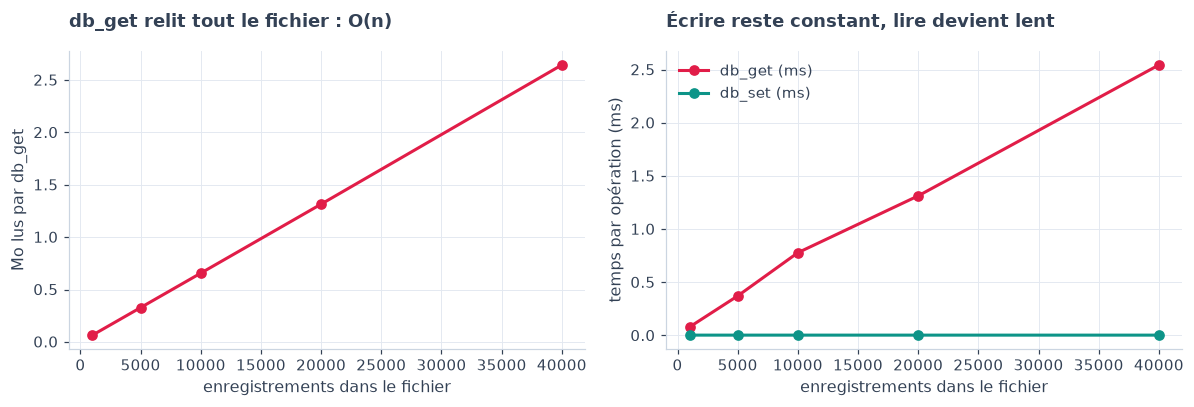

,enregistrements,taille_Mo,us_par_set,ms_par_get,octets_lus_par_get
0,1000,0.065,3.321,0.080,6.478e+04
1,5000,0.328,3.299,0.372,3.277e+05
2,10000,0.657,3.318,0.778,6.566e+05
3,20000,1.315,3.287,1.313,1.315e+06
4,40000,2.644,3.303,2.544,2.644e+06


In [3]:
rows = []
db = S.BashDB(os.path.join(WORK, "bash_perf"))
n_done = 0
for n in [1_000, 5_000, 10_000, 20_000, 40_000]:
    t0 = time.perf_counter()
    for i in range(n_done, n):
        db.set(str(i % (n // 2 + 1)), S.kv_value(i, size=60))
    t_set = (time.perf_counter() - t0) / (n - n_done)
    n_done = n
    db.bytes_scanned = 0
    t0 = time.perf_counter()
    for k in range(5):
        db.get(str(k * 7))
    t_get = (time.perf_counter() - t0) / 5
    rows.append(dict(enregistrements=n, taille_Mo=db.size() / 1e6, us_par_set=t_set * 1e6,
                     ms_par_get=t_get * 1e3, octets_lus_par_get=db.bytes_scanned / 5))
bash = pd.DataFrame(rows)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
ax = axes[0]
ax.plot(bash.enregistrements, bash.octets_lus_par_get / 1e6, "o-", color=ROSE)
ax.set_xlabel("enregistrements dans le fichier"); ax.set_ylabel("Mo lus par db_get")
ax.set_title("db_get relit tout le fichier : O(n)")
ax = axes[1]
ax.plot(bash.enregistrements, bash.ms_par_get, "o-", color=ROSE, label="db_get (ms)")
ax.plot(bash.enregistrements, bash.us_par_set / 1e3, "o-", color=TEAL, label="db_set (ms)")
ax.set_xlabel("enregistrements dans le fichier"); ax.set_ylabel("temps par opération (ms)")
ax.set_title("Écrire reste constant, lire devient lent")
ax.legend()
finish(fig)
plt.show()
bash

Le nombre d'octets lus par `db_get` est exactement la taille du fichier : doubler les
données double le coût d'une lecture. `db_set`, lui, garde un coût constant (quelques
microsecondes, essentiellement l'ouverture du fichier). Un vrai moteur fondé sur un
journal doit en plus gérer les écritures concurrentes, récupérer l'espace des vieilles
versions et survivre aux enregistrements à moitié écrits lors d'une panne : nous y
viendrons en section 5.

> **À retenir.** Ajouter en fin de fichier est l'écriture la plus simple et la plus
> rapide possible. Sans structure supplémentaire, la lecture coûte $O(n)$ : il faut un
> **index**.

## 2. Qu'est-ce qu'un index ? (section *Data Structures That Power Your Database*)

**Définition.** Un index est une structure **supplémentaire, dérivée** des données
primaires, qui sert de panneau indicateur : il dit où trouver ce qu'on cherche. On peut
en ajouter ou en retirer sans changer le **contenu** de la base, seulement la vitesse des
requêtes. Si l'on veut chercher les mêmes données de plusieurs façons, il faut plusieurs
index.

**Le compromis.** Chaque index doit être mis à jour à **chaque écriture**. Un bon index
accélère les lectures, mais tout index coûte de l'espace et ralentit les écritures. C'est
pourquoi les bases n'indexent pas tout par défaut : c'est à vous, qui connaissez les
requêtes de l'application, de choisir.

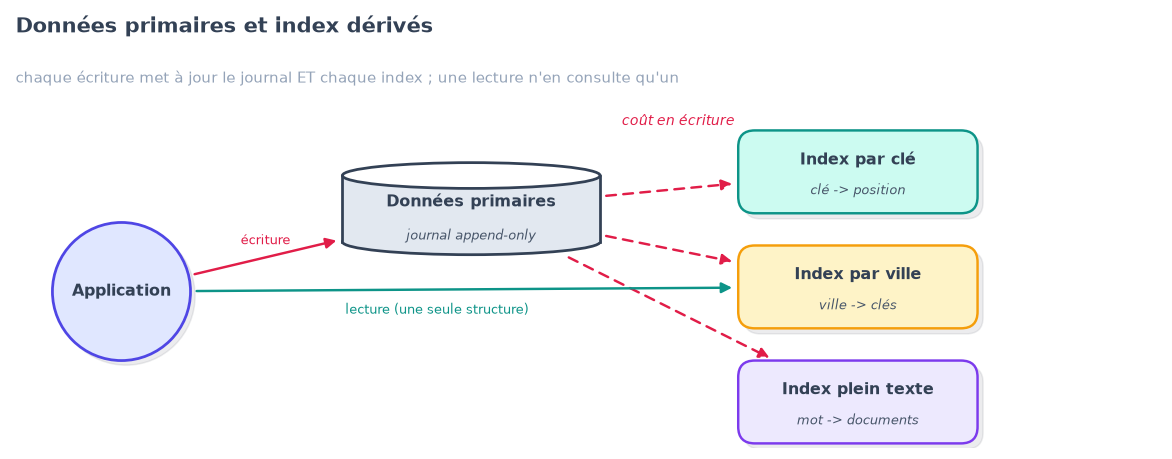

In [4]:
d = Diagram(12.5, 3.8, title="Données primaires et index dérivés",
            subtitle="chaque écriture met à jour le journal ET chaque index ; une lecture n'en consulte qu'un")
d.box("app", 1.2, 1.7, "Application", kind="user", w=1.5, color=INDIGO)
d.box("log", 5.0, 2.6, "Données primaires", sub="journal append-only", color=SLATE, kind="db", w=2.8, h=1.0)
d.box("i1", 9.2, 3.0, "Index par clé", sub="clé -> position", color=TEAL, w=2.6)
d.box("i2", 9.2, 1.75, "Index par ville", sub="ville -> clés", color=AMBER, w=2.6)
d.box("i3", 9.2, 0.5, "Index plein texte", sub="mot -> documents", color=VIOLET, w=2.6)
d.arrow("app", "log", "écriture", color=ROSE)
for i in ("i1", "i2", "i3"):
    d.arrow("log", i, style="dashed", color=ROSE)
d.arrow("app", "i2", "lecture (une seule structure)", color=TEAL, label_pos=0.45, label_offset=(0, -0.22))
d.note(7.25, 3.55, "coût en écriture", color=ROSE)
d.show()

**Mesure.** Le coût d'une écriture croît avec le nombre d'index à maintenir. Simulons des
index en mémoire (des dictionnaires) sur une table de clients et chronométrons 20 000
insertions avec 0 à 6 index.

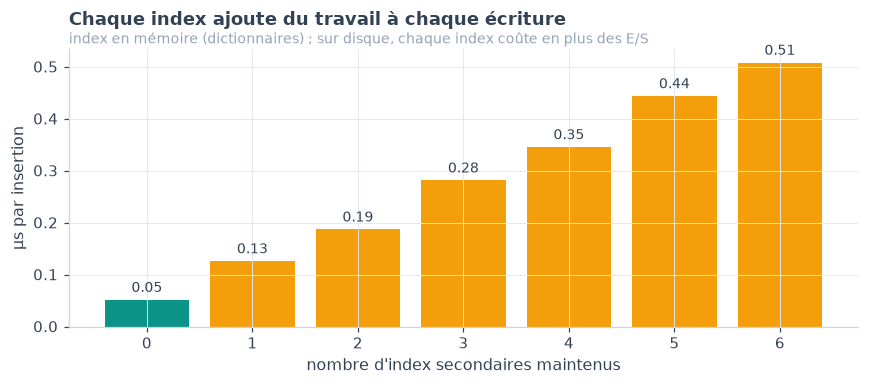

In [5]:
rng = np.random.default_rng(0)
N = 20_000
clients = [dict(id=i, ville=f"v{rng.integers(50)}", age=int(rng.integers(18, 90)),
                nom=f"nom{rng.integers(5000)}", segment=int(rng.integers(5)),
                code=f"c{rng.integers(10**6)}", pays=f"p{rng.integers(30)}") for i in range(N)]
champs = ["ville", "age", "nom", "segment", "code", "pays"]
import gc

mesures = []
for n_index in range(0, 7):
    essais = []
    for _ in range(5):  # on garde le meilleur de 5 essais pour lisser le bruit de mesure
        journal, index = [], {c: {} for c in champs[:n_index]}
        gc.disable()
        t0 = time.perf_counter()
        for row in clients:
            journal.append(row)
            for c, idx in index.items():
                idx.setdefault(row[c], []).append(row["id"])
        essais.append(time.perf_counter() - t0)
        gc.enable()
    mesures.append(dict(index=n_index, us_par_ecriture=min(essais) / N * 1e6))
mes = pd.DataFrame(mesures)
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.bar(mes["index"], mes.us_par_ecriture, color=[TEAL] + [AMBER] * 6)
annotate_bars(ax, "{:.2f}")
ax.set_xlabel("nombre d'index secondaires maintenus"); ax.set_ylabel("µs par insertion")
ax.set_title("Chaque index ajoute du travail à chaque écriture")
subtitle(ax, "index en mémoire (dictionnaires) ; sur disque, chaque index coûte en plus des E/S")
plt.tight_layout(); plt.show()

Le coût par insertion augmente à peu près linéairement avec le nombre d'index : avec six
index, une insertion coûte plusieurs fois l'ajout nu au journal. Sur disque, l'effet est
bien plus marqué, car chaque index peut exiger ses propres lectures et écritures de pages
(nous le mesurerons sur PostgreSQL dans le lab).

> **À retenir.** Un index est une structure dérivée qui accélère certaines lectures au
> prix d'écritures plus lentes et d'espace en plus. Choisir ses index, c'est arbitrer
> selon les requêtes réelles de l'application.

## 3. Un index de hachage en mémoire (section *Hash Indexes*)

**Idée.** Gardons le journal tel quel (écritures rapides), mais tenons **en mémoire** une
table de hachage qui associe à chaque clé la **position** (*offset*, en octets) de sa
valeur la plus récente dans le fichier. Écrire = ajouter au fichier **et** mettre à
jour la table ; lire = consulter la table, se positionner (`seek`) et lire une seule
valeur. Si cette partie du fichier est déjà dans le cache du système de fichiers, la
lecture ne fait même aucune E/S disque.

C'est le principe de **Bitcask**, le moteur par défaut de la base Riak :
performances excellentes tant que toutes les clés tiennent en RAM, ce qui convient bien
à des clés peu nombreuses souvent mises à jour (par exemple un compteur de lectures par
URL de vidéo).

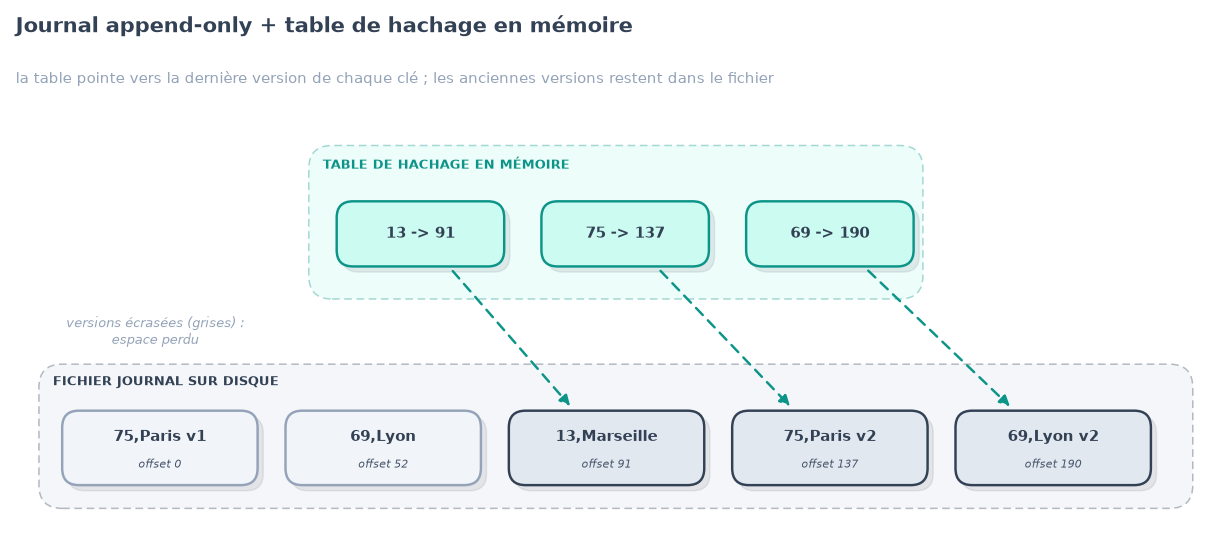

In [6]:
d = Diagram(13, 4.6, title="Journal append-only + table de hachage en mémoire",
            subtitle="la table pointe vers la dernière version de chaque clé ; les anciennes versions restent dans le fichier")
d.group(0.3, 0.2, 12.7, 1.75, "fichier journal sur disque", color=SLATE)
recs = [("75", "Paris v1", 0), ("69", "Lyon", 52), ("13", "Marseille", 91), ("75", "Paris v2", 137),
        ("69", "Lyon v2", 190)]
for j, (k, v, off) in enumerate(recs):
    x = 1.6 + j * 2.4
    old = (k == "75" and j == 0) or (k == "69" and j == 1)
    d.box(f"r{j}", x, 0.85, f"{k},{v}", sub=f"offset {off}", color=GRAY if old else SLATE, w=2.1, h=0.8,
          fontsize=9.5)
d.group(3.2, 2.45, 9.8, 4.1, "table de hachage en mémoire", color=TEAL)
for j, (k, tgt) in enumerate([("13", 2), ("75", 3), ("69", 4)]):
    x = 4.4 + j * 2.2
    d.box(f"h{k}", x, 3.15, f"{k} -> {recs[tgt][2]}", color=TEAL, w=1.8, h=0.7, fontsize=9.5)
    d.arrow(f"h{k}", f"r{tgt}", color=TEAL, style="dashed")
d.note(1.55, 2.1, "versions écrasées (grises) :\nespace perdu", color=GRAY, fontsize=8.5)
d.show()

`S.HashIndexStore` implémente ce moteur avec de vrais fichiers. Chaque enregistrement
est encodé en binaire (section 5) ; l'index associe `clé -> (segment, offset, taille)`.
Comparons le coût d'une lecture avec celui de la base bash, en octets lus.

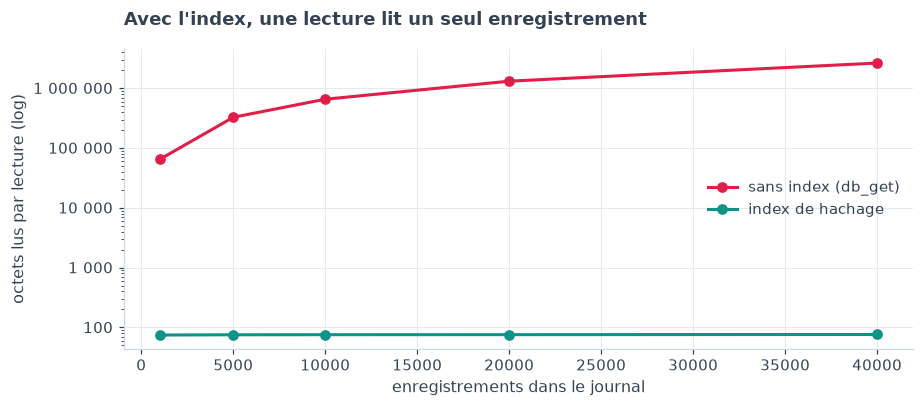

,enregistrements,octets_lus_par_get,us_par_get,cles_en_memoire
0,1000,74.780,1.440,501
1,5000,75.556,3.491,2501
2,10000,75.778,3.454,5001
3,20000,75.889,3.502,10001
4,40000,76.445,3.506,20001


In [7]:
rows = []
for n in [1_000, 5_000, 10_000, 20_000, 40_000]:
    st = S.HashIndexStore(os.path.join(WORK, f"hash_{n}"), segment_bytes=1 << 30)
    for i in range(n):
        st.put(str(i % (n // 2 + 1)), S.kv_value(i, size=60))
    t0 = time.perf_counter()
    for k in range(200):
        st.get(str(k * 7))
    t_get = (time.perf_counter() - t0) / 200
    rows.append(dict(enregistrements=n, octets_lus_par_get=st.live_bytes() / len(st.index),
                     us_par_get=t_get * 1e6, cles_en_memoire=len(st.index)))
    st.close()
hidx = pd.DataFrame(rows)
fig, ax = plt.subplots(figsize=(8.5, 3.8))
ax.plot(bash.enregistrements, bash.octets_lus_par_get, "o-", color=ROSE, label="sans index (db_get)")
ax.plot(hidx.enregistrements, hidx.octets_lus_par_get, "o-", color=TEAL, label="index de hachage")
ax.set_yscale("log"); S.plain_log_ticks(ax)
ax.set_xlabel("enregistrements dans le journal"); ax.set_ylabel("octets lus par lecture (log)")
ax.set_title("Avec l'index, une lecture lit un seul enregistrement")
ax.legend()
plt.tight_layout(); plt.show()
hidx

La lecture passe d'un parcours de plusieurs mégaoctets à la lecture d'un seul
enregistrement (environ 70 octets ici), quelle que soit la taille du journal : le coût
est $O(1)$. Le prix : la table de hachage contient **toutes** les clés et doit tenir en
mémoire (colonne `cles_en_memoire`).

> **À retenir.** Un index de hachage en mémoire sur un journal append-only donne des
> écritures séquentielles rapides et des lectures en une seule E/S. Sa contrainte
> principale : toutes les clés doivent tenir en RAM.

## 4. Segments, fusion et compaction (section *Hash Indexes*)

**Le problème.** Un journal auquel on ne fait qu'ajouter grossit **sans fin**, même si
l'on ne fait que réécrire les mêmes clés : les versions écrasées occupent toujours le
disque.

**La solution.** Couper le journal en **segments** de taille bornée : quand le segment
actif atteint une certaine taille, on le ferme (il devient **immuable**) et on en ouvre un
nouveau. En tâche de fond, on **compacte** les segments fermés : on ne garde que la
dernière valeur de chaque clé, et on peut **fusionner** plusieurs petits segments en un
seul. Les anciens fichiers sont supprimés une fois le nouveau segment prêt ; pendant ce
temps, les lectures continuent sur les anciens segments.

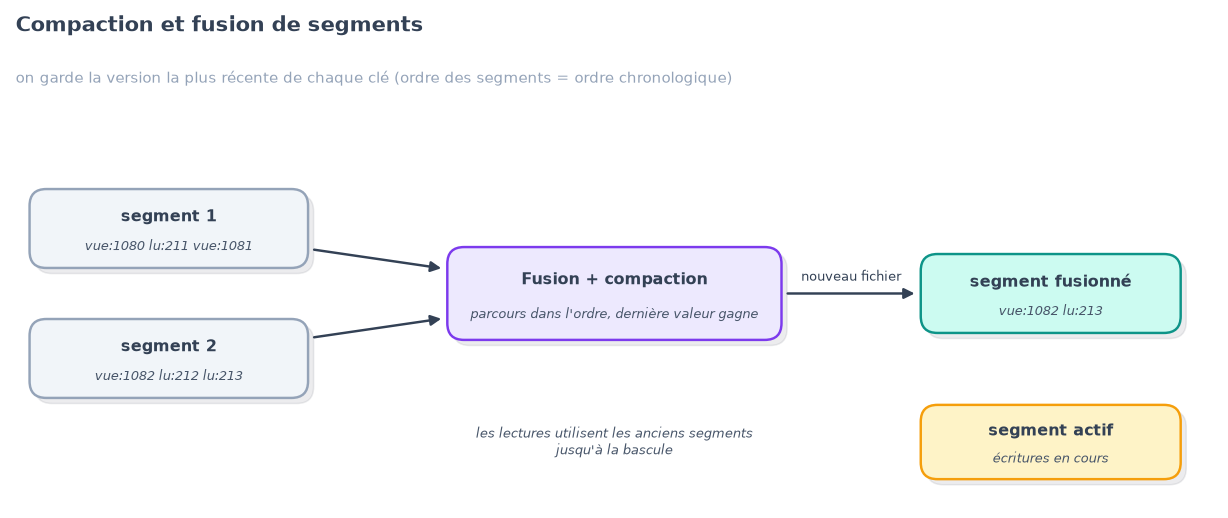

In [8]:
d = Diagram(13, 4.4, title="Compaction et fusion de segments",
            subtitle="on garde la version la plus récente de chaque clé (ordre des segments = ordre chronologique)")
d.box("s1", 1.7, 3.0, "segment 1", sub="vue:1080 lu:211 vue:1081", color=GRAY, w=3.0, h=0.85)
d.box("s2", 1.7, 1.6, "segment 2", sub="vue:1082 lu:212 lu:213", color=GRAY, w=3.0, h=0.85)
d.box("m", 6.5, 2.3, "Fusion + compaction", sub="parcours dans l'ordre, dernière valeur gagne", color=VIOLET,
      w=3.6, h=1.0)
d.box("out", 11.2, 2.3, "segment fusionné", sub="vue:1082 lu:213", color=TEAL, w=2.8, h=0.85)
d.box("act", 11.2, 0.7, "segment actif", sub="écritures en cours", color=AMBER, w=2.8, h=0.8)
d.arrow("s1", "m"); d.arrow("s2", "m"); d.arrow("m", "out", "nouveau fichier")
d.note(6.5, 0.7, "les lectures utilisent les anciens segments\njusqu'à la bascule", fontsize=8.5)
d.show()

**Expérience.** On écrit 60 000 mises à jour sur 2 000 clés (popularité de type Zipf :
quelques clés très chaudes) dans des segments de 64 Kio, en compactant (ou non) tous les
5 000 écritures. On suit l'espace disque occupé et l'espace « vivant » (dernières
versions seulement).

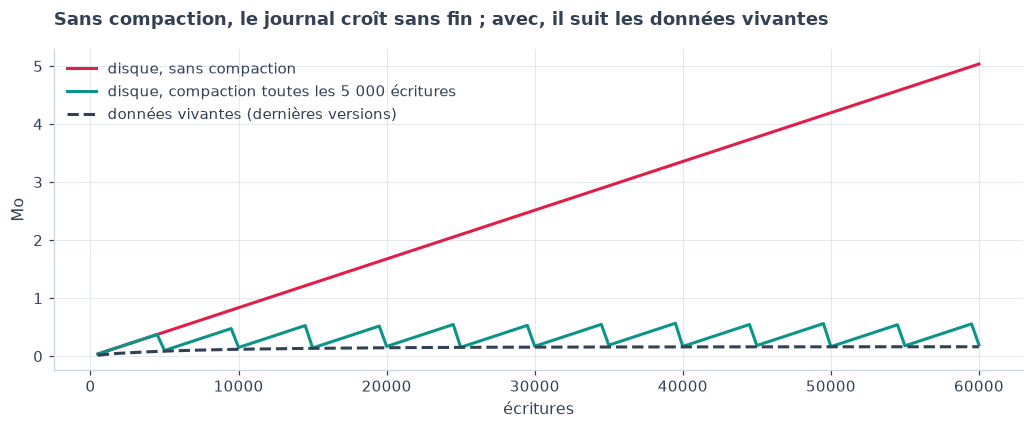

,sans compaction,avec compaction
Mo sur disque à la fin,5.04,0.20
segments,77.00,4.00
Mo réécrits par la compaction,0.00,1.62


In [9]:
def experience_compaction(compacter: bool, n_ops=60_000, n_keys=2_000, every=5_000):
    st = S.HashIndexStore(os.path.join(WORK, f"seg_{compacter}"), segment_bytes=64 * 1024)
    keys = S.zipf_keys(n_ops, n_keys, s=1.0, seed=7)
    trace = []
    for n, i in enumerate(keys, 1):
        st.put(S.kv_key(int(i)), S.kv_value(int(i), n, size=60))
        if compacter and n % every == 0:
            st.compact()
        if n % 500 == 0:
            trace.append(dict(ops=n, disque=st.disk_bytes(), vivant=st.live_bytes(), segments=len(st.segments)))
    out = pd.DataFrame(trace)
    st.close()
    return out, st


sans, st_sans = experience_compaction(False)
avec, st_avec = experience_compaction(True)
fig, ax = plt.subplots(figsize=(9.5, 4))
ax.plot(sans.ops, sans.disque / 1e6, color=ROSE, label="disque, sans compaction")
ax.plot(avec.ops, avec.disque / 1e6, color=TEAL, label="disque, compaction toutes les 5 000 écritures")
ax.plot(avec.ops, avec.vivant / 1e6, color=SLATE, ls="--", label="données vivantes (dernières versions)")
ax.set_xlabel("écritures"); ax.set_ylabel("Mo")
ax.set_title("Sans compaction, le journal croît sans fin ; avec, il suit les données vivantes")
ax.legend()
plt.tight_layout(); plt.show()
pd.DataFrame({"sans compaction": [sans.disque.iloc[-1] / 1e6, sans.segments.iloc[-1], st_sans.compaction_bytes / 1e6],
              "avec compaction": [avec.disque.iloc[-1] / 1e6, avec.segments.iloc[-1], st_avec.compaction_bytes / 1e6]},
             index=["Mo sur disque à la fin", "segments", "Mo réécrits par la compaction"]).round(2)

Sans compaction, l'espace disque croît linéairement avec le nombre d'écritures alors que
les données vivantes plafonnent (2 000 clés). Avec compaction, la courbe dessine des
**dents de scie** : elle monte entre deux compactions puis retombe près des données
vivantes. Le prix est le volume **réécrit** par la compaction (dernière ligne du
tableau) : c'est une première forme d'**amplification d'écriture**, que nous étudierons
en détail aux cours 2 et 3.

> **À retenir.** Segments immuables + compaction en tâche de fond = espace disque borné
> par les données vivantes (plus une marge), au prix de réécritures. L'immuabilité rend
> la compaction sûre : on ne modifie jamais un fichier qu'un lecteur est en train de lire.

## 5. Ce qui fait un vrai moteur (section *Hash Indexes*)

Le livre énumère les questions qu'un moteur réel doit régler. Examinons-les une à une
sur notre implémentation.

**Format de fichier.** Plutôt que du CSV (qui demande d'échapper les virgules), on
encode chaque enregistrement en binaire : longueur de la clé, longueur de la valeur,
puis les octets bruts. Nous ajoutons une **somme de contrôle** (CRC32) en tête.

In [10]:
rec = S.encode_record("75", "Paris")
tomb = S.encode_record("75", None)
pd.DataFrame({"champ": ["crc32", "len(clé)", "len(valeur)", "clé", "valeur"],
              "octets (enregistrement)": [rec[0:4].hex(" "), rec[4:8].hex(" "), rec[8:12].hex(" "), rec[12:14],
                                          rec[14:]],
              "octets (tombstone)": [tomb[0:4].hex(" "), tomb[4:8].hex(" "), tomb[8:12].hex(" "), tomb[12:14], b""]})

,champ,octets (enregistrement),octets (tombstone)
0,crc32,db b4 8d 25,fc 9c 43 14
1,len(clé),00 00 00 02,00 00 00 02
2,len(valeur),00 00 00 05,ff ff ff ff
3,clé,b'75',b'75'
4,valeur,b'Paris',b''


**Suppressions.** On ne peut pas effacer une ligne au milieu d'un fichier immuable : on
ajoute un enregistrement spécial de suppression, un **tombstone** (ici, une longueur de
valeur `ff ff ff ff`). La compaction, en le rencontrant, sait qu'elle doit écarter toutes
les versions précédentes de la clé.

**Reprise après panne.** La table de hachage vit en mémoire : après un redémarrage, elle
est vide. On peut la reconstruire en relisant **tous** les segments, ce qui est lent si
les données sont volumineuses. Bitcask accélère la reprise en sauvegardant sur disque un
instantané de la table de chaque segment (*hint file*), qu'on recharge directement.

**Enregistrements partiellement écrits.** Une panne peut survenir au milieu d'un
ajout. La somme de contrôle permet de détecter et d'ignorer la fin corrompue du
journal. Démonstration : on écrit 1 000 clés, on ajoute la moitié d'un enregistrement
(panne simulée), puis on rouvre le répertoire.

In [11]:
dossier = os.path.join(WORK, "reprise")
st = S.HashIndexStore(dossier, segment_bytes=1 << 20)
for i in range(1000):
    st.put(S.kv_key(i), S.kv_value(i, size=60))
st.delete(S.kv_key(3))
st.close()
taille_avant = os.path.getsize(st._path(st.active))
with open(st._path(st.active), "ab") as f:
    f.write(S.encode_record(S.kv_key(5000), "écriture interrompue par une panne")[:20])
t0 = time.perf_counter()
st2 = S.HashIndexStore.open(dossier, segment_bytes=1 << 20)
dt = time.perf_counter() - t0
pd.Series({"clés reconstruites": len(st2.index), "enregistrements relus": st2.records_scanned,
           "octets relus": st2.bytes_scanned, "taille saine du segment": taille_avant,
           "taille après réouverture": os.path.getsize(st2._path(st.active)),
           "clé supprimée (user00000003)": str(st2.get(S.kv_key(3))),
           "clé à moitié écrite": str(st2.get(S.kv_key(5000))),
           "durée de reconstruction (ms)": round(dt * 1e3, 1)}, dtype=object).to_frame("valeur")

,valeur
clés reconstruites,999
enregistrements relus,1001
octets relus,84044
taille saine du segment,84024
taille après réouverture,84024
clé supprimée (user00000003),None
clé à moitié écrite,None
durée de reconstruction (ms),0.5


Les 1 001 enregistrements valides (1 000 écritures + 1 tombstone) sont relus, la clé
supprimée reste absente, et les 20 octets de l'enregistrement interrompu sont détectés
(longueur incohérente) puis tronqués : le segment retrouve sa taille saine. La durée de
reconstruction est proportionnelle au volume relu ; à l'échelle de centaines de Go, elle
se compterait en minutes, d'où les fichiers d'indices.

**Concurrence.** Les écritures sont strictement séquentielles : on n'autorise
généralement **qu'un seul fil d'écriture**. Les segments fermés étant immuables, on peut
les lire depuis plusieurs fils en parallèle, et la compaction travaille dans son propre
fil. Le diagramme espace-temps ci-dessous montre ce partage du travail : l'écrivain
continue d'ajouter au segment actif pendant que le compacteur fusionne les segments
fermés, puis une bascule atomique remplace les anciens fichiers.

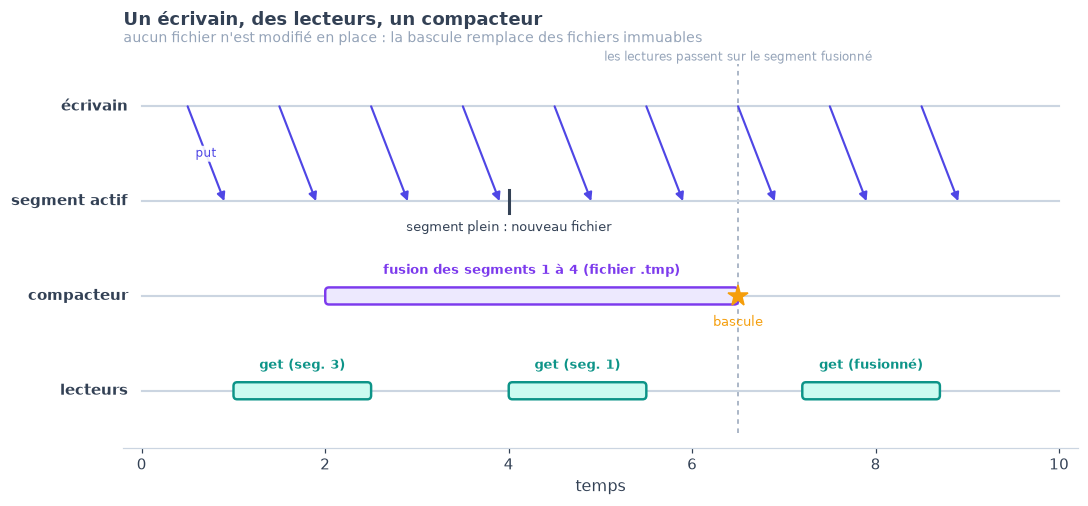

In [12]:
st = SpaceTime(["écrivain", "segment actif", "compacteur", "lecteurs"], t_max=10,
               title="Un écrivain, des lecteurs, un compacteur",
               subtitle="aucun fichier n'est modifié en place : la bascule remplace des fichiers immuables")
for t in [0.5, 1.5, 2.5, 3.5, 4.5, 5.5, 6.5, 7.5, 8.5]:
    st.msg("écrivain", t, "segment actif", t + 0.4, "put" if t < 1 else "", color=INDIGO)
st.op("compacteur", 2.0, 6.5, "fusion des segments 1 à 4 (fichier .tmp)", color=VIOLET)
st.event("compacteur", 6.5, "bascule", kind="star")
st.vline(6.5, "les lectures passent sur le segment fusionné")
st.op("lecteurs", 1.0, 2.5, "get (seg. 3)", color=TEAL)
st.op("lecteurs", 4.0, 5.5, "get (seg. 1)", color=TEAL)
st.op("lecteurs", 7.2, 8.7, "get (fusionné)", color=TEAL)
st.event("segment actif", 4.0, "segment plein : nouveau fichier", kind="tick")
st.show()

> **À retenir.** Un moteur à journal réel ajoute : un format binaire avec somme de
> contrôle (écritures partielles), des tombstones (suppressions), une reprise rapide de
> l'index (instantanés) et un modèle de concurrence simple (un écrivain, des lecteurs,
> des fichiers immuables).

## 6. Pourquoi ajouter plutôt que modifier en place ? Les limites du hachage (section *Hash Indexes*)

On pourrait écraser l'ancienne valeur à sa place dans le fichier. Le journal
append-only a pourtant trois avantages :

1. **les écritures sont séquentielles**, bien plus rapides que des écritures aléatoires,
   surtout sur disque magnétique (et encore sensiblement sur SSD, cours 3) ;
2. **la reprise après panne est simple** : seule la fin du dernier fichier peut être
   abîmée, jamais une valeur ancienne à moitié écrasée ;
3. **la fusion évite la fragmentation** du fichier au fil du temps.

Le modèle de disque `S.io_time` (ordres de grandeur typiques) chiffre le premier point
pour 100 000 écritures de 100 octets.

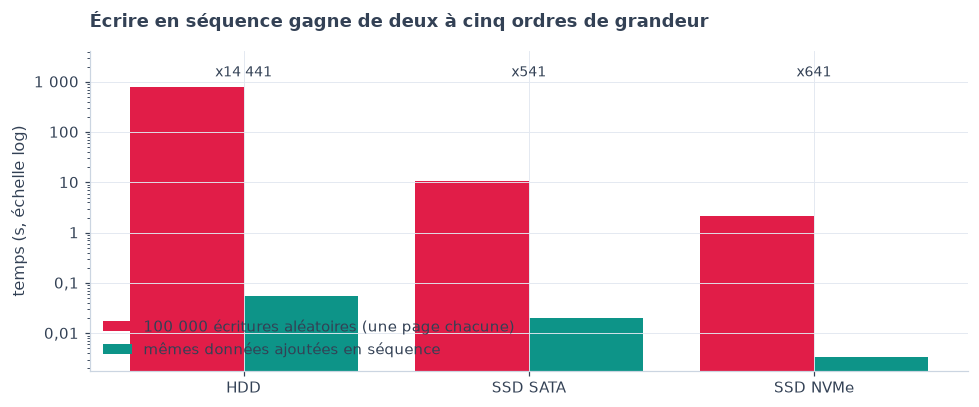

In [13]:
n, taille = 100_000, 100
lignes = []
for dev in S.DEVICES:
    aleatoire = S.io_time(dev, n_random=n)
    sequentiel = S.io_time(dev, seq_bytes=n * taille)
    lignes.append(dict(support=dev, aleatoire_s=aleatoire, sequentiel_s=sequentiel, rapport=aleatoire / sequentiel))
io = pd.DataFrame(lignes)
fig, ax = plt.subplots(figsize=(9, 3.8))
x = np.arange(len(io))
ax.bar(x - 0.2, io.aleatoire_s, 0.4, color=ROSE, label="100 000 écritures aléatoires (une page chacune)")
ax.bar(x + 0.2, io.sequentiel_s, 0.4, color=TEAL, label="mêmes données ajoutées en séquence")
ax.set_yscale("log"); S.plain_log_ticks(ax); ax.set_xticks(x, io.support)
ax.set_ylabel("temps (s, échelle log)")
ax.set_title("Écrire en séquence gagne de deux à cinq ordres de grandeur")
for xi, r in zip(x, io.rapport):
    ax.text(xi, io.aleatoire_s.max() * 1.6, f"x{r:,.0f}".replace(",", " "), ha="center", color=SLATE, fontsize=9)
ax.set_ylim(top=io.aleatoire_s.max() * 5)
ax.legend(loc="lower left")
plt.tight_layout(); plt.show()

Le modèle est simpliste (il ignore les caches d'écriture et le parallélisme interne des
SSD) mais l'ordre de grandeur est juste : une écriture aléatoire paie un déplacement de
tête (HDD) ou au minimum une page entière, alors qu'un ajout séquentiel ne paie que ses
octets.

**Les limites de l'index de hachage** sont tout aussi nettes :

- **toutes les clés doivent tenir en mémoire**. Une table de hachage sur disque est
  difficile à rendre performante : beaucoup d'E/S aléatoires, agrandissement coûteux,
  collisions délicates ;
- **les requêtes par intervalle sont inefficaces** : pour lire toutes les clés entre
  `user00010000` et `user00019999`, il faut les chercher une par une (la table n'a
  aucun ordre), ou tout parcourir.

Chiffrons la mémoire nécessaire : environ (taille de la clé + 40 octets de surcoût par
entrée d'un dictionnaire) par clé.

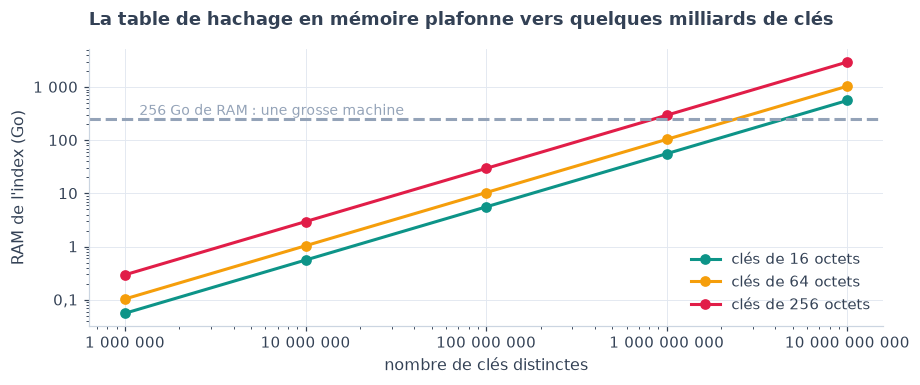

In [14]:
cles = np.array([1e6, 1e7, 1e8, 1e9, 1e10])
fig, ax = plt.subplots(figsize=(8.5, 3.6))
for kb, c in [(16, TEAL), (64, AMBER), (256, ROSE)]:
    ax.plot(cles, cles * (kb + 40) / 1e9, "o-", color=c, label=f"clés de {kb} octets")
ax.axhline(256, color=GRAY, ls="--"); ax.text(1.2e6, 300, "256 Go de RAM : une grosse machine", color=GRAY, fontsize=9)
ax.set_xscale("log"); ax.set_yscale("log"); S.plain_log_ticks(ax, "both")
ax.set_xlabel("nombre de clés distinctes"); ax.set_ylabel("RAM de l'index (Go)")
ax.set_title("La table de hachage en mémoire plafonne vers quelques milliards de clés")
ax.legend()
plt.tight_layout(); plt.show()

Au-delà de quelques milliards de clés, l'index ne tient plus sur une machine. Les deux
limites (mémoire et intervalles) motivent la structure suivante : des segments **triés
par clé**, les SSTables, qui permettent un index **épars** et des parcours ordonnés
(cours 2).

> **À retenir.** Le journal append-only gagne sur les écritures (séquentielles), la
> reprise et la fragmentation. L'index de hachage, lui, exige que toutes les clés
> tiennent en RAM et ne sait pas répondre aux requêtes par intervalle.